# 📄 Real-Time Document Corner Detection & Edge Deployment with YOLOv8-Seg

**An end-to-end Computer Vision pipeline for document boundary segmentation, strict 4-corner extraction, and low-latency mobile deployment on Android.**

---

### 📌 Overview & Architecture
Document scanning in mobile environments requires detecting document boundaries with extreme precision across diverse conditions: wrinkled or curved receipts, oblique camera perspectives, multi-page book bindings, finger occlusions, and chaotic background clutter.

This notebook implements the complete research and production pipeline:
1. **Targeted Dataset Streaming:** Selective downloading of 7 specialized corpora without local disk overflow.
2. **Synthetic Data Synthesis:** Procedural generation of adjacent-page bleed and zero-margin full-bleed edge cases.
3. **Master YOLOv8-Seg Formatting:** Homogeneous conversion of complex polygons, masks, and quads into normalized segmentation labels.
4. **YOLOv8n-Seg Optimization:** Training an ultra-lightweight instance segmentation architecture tailored for edge inference.
5. **Geometric Post-Processing:** Adaptive ConvexHull and RDP simplification to extract strictly 4 ordered document corners (`[TL, TR, BR, BL]`).
6. **Hardware-Accelerated In-Browser & Local Webcam Inference:** Asynchronous streaming with client-side canvas overlay rendering.
7. **Mobile Edge Quantization:** Exporting model weights to FP16 and INT8 TensorFlow Lite (TFLite) for Android deployment.

---

### 📂 Standalone Modular Repository Mapping
For production development outside of Google Colab, this pipeline has been refactored into a modular local repository:

| Pipeline Stage | Notebook Cell | Modular Script | Description |
|---|:---:|---|---|
| **Data Acquisition** | Cells 1–6 | `data_prep/download_datasets.py` | Streaming, unzipping, and parsing Hugging Face & public datasets |
| **YOLO Formatting** | Cells 7–10 | `data_prep/build_yolo_format.py` | Synthetic generation, polygon normalization & `dataset.yaml` |
| **Model Training** | Cell 11 | `training/train.py` | Ultralytics YOLOv8-seg training loop with early stopping |
| **Evaluation & Metrics**| Cell 13 | `training/test.py` | Validation pipeline, Box/Mask mAP metrics & diagnostic reporting |
| **Post-Processing** | Cell 13 | `src/postprocess.py` | Convex hull, adaptive epsilon sweep & perspective warp math |
| **Single-Image Inference**| Cells 14–15| `src/infer.py` | Single-image corner detection, overlay drawing & de-warping |
| **Live Webcam** | Cells 15–16 | `src/webcam.py` | Local OpenCV camera capture (`cv2.VideoCapture(0)`) |
| **TFLite Export** | Cells 12, 17 | `src/export.py` | PyTorch (`best.pt`) to FP16 & INT8 TFLite export |

---

### 🎯 Dataset Strategy Matrix
Every dataset addresses a distinct failure mode encountered in real-world mobile capture:

| Dataset | Split | Quantity | Failure Mode / Real-World Challenge Addressed |
|---|:---:|:---:|---|
| **DocCorner** | Train | ~2,000 | **Baseline:** Flat documents on plain desktop surfaces in uniform lighting. |
| **Doc3D** | Train | ~1,500 | **Curvature & Creases:** 3D warped meshes, bent book pages, and crumpled receipts. |
| **MIDV-500** | Train | ~400 | **Occlusion & Clutter:** Finger/thumb holds on edges, textured desks, keyboards. |
| **SmartDoc 2015** | Train | ~30 | **Extreme Perspectives:** Mobile camera video captures at steep oblique angles. |
| **CORD-v2** | Train | ~800 | **Full-Bleed Snapping:** Receipts touching or exceeding image boundaries. |
| **Synthetic Data** | Train | ~1,300 | **Adjacent Pages:** Open book spines and overlapping distractor documents. |
| **DocLayNet** | Aux | ~1,500 | **Texture Source:** Digital PDF layouts used strictly for synthetic generation. |
| **Mendeley Corner** | **Val Only** | ~1,100 | **Final Benchmark:** Pristine smartphone captures used exclusively for validation. |

> **Modular Script Reference:** `data_prep/download_datasets.py` (`_get_hf_token()` and `_hf_login()`)

## 1. Environment Setup & Hugging Face Authentication

Several source datasets (`StonyBrook-CVLab/doc3D-dataset`, `docling-project/DocLayNet-v1.2`) are hosted in gated Hugging Face repositories. 
- In Colab, we authenticate via `google.colab.userdata.get('HF_TOKEN')`.
- In the local repository, authentication is handled via the `HF_TOKEN` environment variable.

In [ ]:
# @title 1. Setup & Hugging Face Authentication
!pip install -q datasets huggingface_hub

import os
from google.colab import userdata
from huggingface_hub import login

# Fetch token from Colab Secrets
hf_token = userdata.get('HF_TOKEN')
os.environ["HF_TOKEN"] = hf_token

# Login to Hugging Face
login(token=hf_token)
print("✅ Hugging Face authenticated successfully!")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


✅ Hugging Face authenticated successfully!


> **Modular Script Reference:** `data_prep/download_datasets.py` (`download_doc_corner()`, `download_cord()`, `download_doclaynet()`)

## 2. Dataset Acquisition: Streaming Subsets (Zero Disk Overflow)

Standard document datasets often exceed 50–100 GB in uncompressed format, causing immediate disk overflow on cloud and local instances. Using Hugging Face's `streaming=True` iterator, we stream and extract only the target sample counts:
- **DocCornerDataset (2,000 images):** Extracts normalized 4-corner coordinates `[TL, TR, BR, BL]`, skipping negative images (frames containing no document).
- **CORD-v2 (800 images):** Downloads full-bleed receipt layouts with ground-truth OCR bounding boxes.
- **DocLayNet-v1.2 (1,500 images):** Retains raw document texture images for downstream multi-page synthetic synthesis.

In [ ]:
# @title Cell 2: Stream and Save Target Subsets (Zero Disk Overflow)
import os
import json
from datasets import load_dataset
from PIL import Image
from tqdm.auto import tqdm

BASE_DIR = "/content/raw_datasets"
os.makedirs(f"{BASE_DIR}/doc_corner/images", exist_ok=True)
os.makedirs(f"{BASE_DIR}/cord/images", exist_ok=True)
os.makedirs(f"{BASE_DIR}/doclaynet/images", exist_ok=True)

# ---------------------------------------------------------------------
# 1. DocCornerDataset (Baseline Corners - 2,000 images)
# ---------------------------------------------------------------------
print("📥 1. Streaming DocCornerDataset...")
ds_corner = load_dataset("mapo80/DocCornerDataset", split="train", streaming=True)
corner_annotations = {}

count = 0
MAX_CORNER = 2000

for item in tqdm(ds_corner, total=MAX_CORNER, desc="DocCorner"):
    # Skip negative samples (images with no document)
    if item.get("is_negative", False):
        continue

    img_id = f"corner_{count:05d}"
    img_path = f"{BASE_DIR}/doc_corner/images/{img_id}.jpg"

    img = item["image"].convert("RGB")
    w, h = img.size
    img.save(img_path, quality=90)

    # Save normalized corner coordinates [TL, TR, BR, BL]
    corner_annotations[f"{img_id}.jpg"] = {
        "width": w,
        "height": h,
        "corners": [
            [item["corner_tl_x"], item["corner_tl_y"]],
            [item["corner_tr_x"], item["corner_tr_y"]],
            [item["corner_br_x"], item["corner_br_y"]],
            [item["corner_bl_x"], item["corner_bl_y"]],
        ]
    }

    count += 1
    if count >= MAX_CORNER:
        break

with open(f"{BASE_DIR}/doc_corner/annotations.json", "w") as f:
    json.dump(corner_annotations, f, indent=2)
print(f"✅ DocCorner saved: {count} images.")

# ---------------------------------------------------------------------
# 2. CORD-v2 (Receipt Layouts - 800 images)
# ---------------------------------------------------------------------
print("\n📥 2. Streaming CORD-v2...")
ds_cord = load_dataset("naver-clova-ix/cord-v2", split="train", streaming=True)
cord_annotations = {}

count = 0
MAX_CORD = 800

for item in tqdm(ds_cord, total=MAX_CORD, desc="CORD"):
    img_id = f"cord_{count:05d}"
    img_path = f"{BASE_DIR}/cord/images/{img_id}.jpg"

    img = item["image"].convert("RGB")
    w, h = img.size
    img.save(img_path, quality=90)

    gt = item.get("ground_truth")
    if isinstance(gt, str):
        gt = json.loads(gt)

    cord_annotations[f"{img_id}.jpg"] = {
        "width": w,
        "height": h,
        "raw_gt": gt
    }

    count += 1
    if count >= MAX_CORD:
        break

with open(f"{BASE_DIR}/cord/annotations.json", "w") as f:
    json.dump(cord_annotations, f, indent=2)
print(f"✅ CORD saved: {count} images.")

# ---------------------------------------------------------------------
# 3. DocLayNet (A4 Document Layouts - 1,500 images)
# ---------------------------------------------------------------------
print("\n📥 3. Streaming DocLayNet...")
ds_doclaynet = load_dataset(
    "docling-project/DocLayNet-v1.2",
    name="default",
    split="train",
    streaming=True
)

count = 0
MAX_DOCLAYNET = 1500

for item in tqdm(ds_doclaynet, total=MAX_DOCLAYNET, desc="DocLayNet"):
    img_id = f"doclaynet_{count:05d}"
    img_path = f"{BASE_DIR}/doclaynet/images/{img_id}.jpg"

    img = item["image"].convert("RGB")
    img.save(img_path, quality=85)

    count += 1
    if count >= MAX_DOCLAYNET:
        break

print(f"✅ DocLayNet saved: {count} images.")

# Verify final disk usage
print("\n📊 Final Disk Usage:")
!df -h /

📥 1. Streaming DocCornerDataset...


README.md:   0%|          | 0.00/12.7k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/33 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/33 [00:00<?, ?it/s]

DocCorner:   0%|          | 0/2000 [00:00<?, ?it/s]

✅ DocCorner saved: 2000 images.

📥 2. Streaming CORD-v2...


... (5 outputs left out)

Resolving data files:   0%|          | 0/72 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/72 [00:00<?, ?it/s]

DocLayNet:   0%|          | 0/1500 [00:00<?, ?it/s]

✅ DocLayNet saved: 1500 images.

📊 Final Disk Usage:
Filesystem      Size  Used Avail Use% Mounted on
overlay         113G  898M  112G   1% /


> **Modular Script Reference:** `data_prep/download_datasets.py` (`download_doc3d()`)

### 2.1 Doc3D: Warped & Curved Document Modeling via Albedo Masks

Real-world documents are rarely perfectly flat. Books, crumpled receipts, and magazines exhibit 3D non-planar surfaces.
- We download paired subsets from `StonyBrook-CVLab/doc3D-dataset`: the 3D-rendered warped images (`img_*.zip`) and their official albedo passes (`alb_*.zip`).
- In the albedo pass, the background void is rendered strictly as pitch-black `[0, 0, 0]`, while paper texels have intensity $> 15$.
- Binarizing the albedo pass ($	ext{intensity} > 15$) and applying morphological closing (`cv2.MORPH_CLOSE`, $3 	imes 3$ kernel) yields pixel-exact segmentation masks regardless of page curvature.

In [ ]:
# @title Cell 3: Fast Doc3D Download & Flawless Albedo Mask Extraction
import os
import zipfile
import shutil
import cv2
import numpy as np
from PIL import Image
from tqdm.auto import tqdm
from huggingface_hub import HfApi, hf_hub_download

BASE_DIR = "/content/raw_datasets/doc3d"
IMG_DIR = f"{BASE_DIR}/images"
MASK_DIR = f"{BASE_DIR}/masks"
TMP_DIR = "/content/tmp_doc3d"

# Wipe old directories to ensure a clean slate
shutil.rmtree(IMG_DIR, ignore_errors=True)
shutil.rmtree(MASK_DIR, ignore_errors=True)
shutil.rmtree(TMP_DIR, ignore_errors=True)

os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(MASK_DIR, exist_ok=True)
os.makedirs(TMP_DIR, exist_ok=True)

hf_token = os.environ.get("HF_TOKEN")
if not hf_token:
    raise ValueError("HF_TOKEN is missing! Run your Hugging Face Auth cell first.")

api = HfApi(token=hf_token)
repo_id = "StonyBrook-CVLab/doc3D-dataset"

print("🔍 Locating image and albedo archives in Hugging Face repository...")
all_files = api.list_repo_files(repo_id, repo_type="dataset")

img_zips = [f for f in all_files if "img_" in f.lower() and f.endswith(".zip")]
if not img_zips:
    raise ValueError("Could not find image zip archives.")
target_img_zip = img_zips[0]

# Automatically match img_1.zip -> alb_1.zip (289 MB)
target_alb_zip = target_img_zip.replace("img_", "alb_")
if target_alb_zip not in all_files:
    alb_zips = [f for f in all_files if "alb_" in f.lower() and f.endswith(".zip")]
    target_alb_zip = alb_zips[0] if alb_zips else None

if not target_alb_zip:
    raise ValueError("Could not locate matching albedo (alb) zip archive.")

print(f"📥 Downloading warped images (~1.25 GB): {target_img_zip}")
img_zip_path = hf_hub_download(
    repo_id=repo_id, filename=target_img_zip, repo_type="dataset", token=hf_token, local_dir=TMP_DIR
)

print(f"📥 Downloading official albedo ground-truth (~289 MB): {target_alb_zip}")
alb_zip_path = hf_hub_download(
    repo_id=repo_id, filename=target_alb_zip, repo_type="dataset", token=hf_token, local_dir=TMP_DIR
)

MAX_DOC3D = 1500
success = 0

print(f"📦 Extracting up to {MAX_DOC3D} samples with pixel-exact paper masks...")
with zipfile.ZipFile(img_zip_path, "r") as z_img, zipfile.ZipFile(alb_zip_path, "r") as z_alb:
    img_members = [f for f in z_img.namelist() if f.lower().endswith((".png", ".jpg", ".jpeg"))]

    # Index ALBEDO files by relative path AND by base filename for fail-safe matching
    alb_map = {}
    for m in z_alb.namelist():
        if m.lower().endswith((".png", ".jpg", ".jpeg")):
            # Clean relative path key (e.g., '1/1_1_1.png')
            rel_key = m.replace("alb/", "").replace("img/", "").strip("/")
            alb_map[rel_key] = m
            # Base ID key (e.g., '1_1_1')
            base_key = os.path.splitext(os.path.basename(m))[0]
            alb_map[base_key] = m

    for img_path_in_zip in tqdm(img_members[:MAX_DOC3D], desc="Extracting Pairs"):
        img_id = f"doc3d_{success:05d}"

        # 1. Save RGB Image
        with z_img.open(img_path_in_zip) as f_img:
            Image.open(f_img).convert("RGB").save(f"{IMG_DIR}/{img_id}.jpg", quality=90)

        # 2. Match Albedo File
        rel_key = img_path_in_zip.replace("img/", "").replace("alb/", "").strip("/")
        base_key = os.path.splitext(os.path.basename(img_path_in_zip))[0]

        alb_member = alb_map.get(rel_key) or alb_map.get(base_key)

        if alb_member:
            with z_alb.open(alb_member) as f_alb:
                file_bytes = np.asarray(bytearray(f_alb.read()), dtype=np.uint8)
                # Decode strictly as 3-channel BGR to bypass alpha channel corruption
                alb_bgr = cv2.imdecode(file_bytes, cv2.IMREAD_COLOR)

                if alb_bgr is not None:
                    # In Albedo passes, the background render void is strictly pitch-black [0, 0, 0]
                    # Paper texture has color values > 15
                    mask = (np.max(alb_bgr, axis=2) > 15).astype(np.uint8) * 255

                    # Morphological closing to seal minor edge aliasing
                    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
                    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

                    cv2.imwrite(f"{MASK_DIR}/{img_id}.png", mask)
        else:
            # Fallback mask if albedo file was missing for this specific frame
            img_bgr = cv2.imread(f"{IMG_DIR}/{img_id}.jpg")
            gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
            _, mask = cv2.threshold(gray, 15, 255, cv2.THRESH_BINARY)
            cv2.imwrite(f"{MASK_DIR}/{img_id}.png", mask)

        success += 1

# Clean temporary download directory
if os.path.exists(TMP_DIR):
    shutil.rmtree(TMP_DIR)

print("=" * 50)
print(f"✅ Doc3D Ground-Truth Extraction Complete!")
print(f"   Images: {len(os.listdir(IMG_DIR))} saved to {IMG_DIR}")
print(f"   Masks:  {len(os.listdir(MASK_DIR))} saved to {MASK_DIR}")
print("=" * 50)

🔍 Locating image and albedo archives in Hugging Face repository...
📥 Downloading warped images (~1.25 GB): doc3d/img_1.zip


doc3d/img_1.zip: reconstructing file:   0%|          |  0.00B / 1.25GB            

doc3d/img_1.zip: downloading bytes:           |  0.00B            

📥 Downloading official albedo ground-truth (~289 MB): doc3d/alb_1.zip


doc3d/alb_1.zip: reconstructing file:   0%|          |  0.00B /  289MB            

doc3d/alb_1.zip: downloading bytes:           |  0.00B            

📦 Extracting up to 1500 samples with pixel-exact paper masks...


Extracting Pairs:   0%|          | 0/1500 [00:00<?, ?it/s]

✅ Doc3D Ground-Truth Extraction Complete!
   Images: 1500 saved to /content/raw_datasets/doc3d/images
   Masks:  1500 saved to /content/raw_datasets/doc3d/masks


> **Modular Script Reference:** `data_prep/download_datasets.py` (`download_midv500()`)

### 2.2 MIDV-500: Clutter, Thumb Occlusions & Table Textures

Mobile captures often include user fingers or thumbs holding document edges, keyboards, and distracting desktop clutter. 
- We download Template 01 (`01_alb_id.zip`) from the SmartEngines repository.
- Each sample contains a high-resolution TIFF capture and an accompanying ground-truth quadrilateral (`quad`).
- The dataset is pruned to 400 balanced image–annotation pairs to prevent category bias while providing strong occlusion invariance.

In [ ]:
# @title Cell 4: Download & Prune MIDV-500 (400 samples)
import os
import glob
import zipfile

BASE_DIR = "/content/raw_datasets/midv500"
os.makedirs(BASE_DIR, exist_ok=True)
zip_path = "/content/midv_01.zip"

print("📥 Downloading MIDV-500 Template 01 (01_alb_id.zip)...")
# Actual filename on SmartEngines FTP server (contains both images and ground_truth JSONs)
!curl -f -# -o {zip_path} "ftp://smartengines.com/midv-500/dataset/01_alb_id.zip"

if not os.path.exists(zip_path) or os.path.getsize(zip_path) < 10000:
    print("⚠️ Direct FTP blocked or unreachable. Trying via midv500 python package...")
    !pip install -q midv500
    import midv500
    midv500.download_dataset(BASE_DIR, "01_alb_id")
else:
    print("📦 Extracting archive...")
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(BASE_DIR)
    os.remove(zip_path)

print("✂️ Pruning to 400 samples...")
img_files = sorted(glob.glob(f"{BASE_DIR}/**/*.tif", recursive=True))

LIMIT = 400
for i, img_path in enumerate(img_files):
    if i >= LIMIT:
        os.remove(img_path)
        # Match and delete corresponding ground_truth JSON
        json_path = img_path.replace("/images/", "/ground_truth/").replace(".tif", ".json")
        if os.path.exists(json_path):
            os.remove(json_path)

remaining = len(glob.glob(f"{BASE_DIR}/**/*.tif", recursive=True))
print(f"✅ MIDV-500 ready: Kept {remaining} images and their matching ground_truth JSONs.")

📥 Downloading MIDV-500 Template 01 (01_alb_id.zip)...
######################################################################## 100.0%
📦 Extracting archive...
✂️ Pruning to 400 samples...
✅ MIDV-500 ready: Kept 301 images and their matching ground_truth JSONs.


> **Modular Script Reference:** `data_prep/download_datasets.py` (`download_smartdoc15()`)

### 2.3 SmartDoc 2015: Oblique Perspectives & High-Angle Mobile Video

Captured from handheld video recordings, SmartDoc 2015 tests detection under steep, non-orthogonal viewing angles.
- We stream the frames tarball directly and extract exactly **one optimal frame per video clip** ($	ext{frame\_index} \ge 50$) to avoid initial camera autofocus hunting and motion blur.
- Polygon annotations from the embedded CSV metadata are parsed and normalized.

In [ ]:
# @title Cell 5: Stream SmartDoc 2015 - 1 Optimal Frame per Video (wget Fix)
import os
import re
import json
import tarfile
import cv2
import gzip
import shutil
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

BASE_DIR = "/content/raw_datasets/smartdoc15"
IMG_DIR = f"{BASE_DIR}/images"
TMP_DIR = "/content/tmp_smartdoc"
os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(TMP_DIR, exist_ok=True)

frames_url = "https://github.com/jchazalon/smartdoc15-ch1-dataset/releases/download/v2.0.0/frames.tar.gz"
tmp_archive = os.path.join(TMP_DIR, "frames.tar.gz")

# 1. Use system 'wget' to bypass Python requests 504 timeouts on Colab
if not os.path.exists(tmp_archive):
    print(f"📥 Downloading SmartDoc 2015 archive via wget...")
    # -c ensures it can resume, -q --show-progress gives a clean progress bar
    exit_code = os.system(f"wget -c -q --show-progress -O {tmp_archive} {frames_url}")

    if exit_code != 0 or not os.path.exists(tmp_archive):
        raise RuntimeError("wget failed to download the SmartDoc archive. GitHub might be temporarily blocking the Colab IP.")

# 2. Extract exactly 1 optimal frame per video from the local archive
print(f"📦 Extracting optimal frames from local archive...")
df = None
extracted_clips = {}

with tarfile.open(tmp_archive, mode="r:gz") as tar:
    with tqdm(desc="SmartDoc Clips", unit=" clip") as pbar:
        for member in tar:
            name_lower = member.name.lower()

            # A. Grab the embedded CSV metadata
            if df is None and (name_lower.endswith(".csv") or name_lower.endswith(".csv.gz")):
                f_in = tar.extractfile(member)
                if f_in:
                    if name_lower.endswith(".gz"):
                        with gzip.GzipFile(fileobj=f_in) as gz:
                            df = pd.read_csv(gz)
                    else:
                        df = pd.read_csv(f_in)

            # B. Extract exactly 1 frame per video folder (frame >= 50 for autofocus stability)
            elif member.isfile() and name_lower.endswith(('.png', '.jpg', '.jpeg')):
                frame_match = re.search(r'(\d+)\.(?:jpeg|jpg|png)', name_lower)

                if frame_match:
                    frame_idx = int(frame_match.group(1))
                    folder_path = os.path.dirname(member.name)
                    clip_name = folder_path.replace('/', '_').replace('\\', '_').strip('_')

                    if frame_idx >= 50 and clip_name not in extracted_clips:
                        f_in = tar.extractfile(member)
                        if f_in:
                            file_bytes = np.asarray(bytearray(f_in.read()), dtype=np.uint8)
                            img = cv2.imdecode(file_bytes, cv2.IMREAD_COLOR)

                            if img is not None:
                                out_name = f"smartdoc_{clip_name}.jpg"
                                out_path = os.path.join(IMG_DIR, out_name)
                                cv2.imwrite(out_path, img, [cv2.IMWRITE_JPEG_QUALITY, 95])

                                extracted_clips[clip_name] = {
                                    "original_path": member.name,
                                    "width": img.shape[1],
                                    "height": img.shape[0]
                                }
                                pbar.update(1)

if df is None:
    raise ValueError("Extraction finished but could not find the embedded CSV metadata.")

# 3. Clean up the 1GB+ tar file to free Colab disk space
shutil.rmtree(TMP_DIR, ignore_errors=True)

# 4. Map coordinates to annotations dictionary
print(f"⚙️ Mapping ground-truth coordinates...")
final_annotations = {}
for clip_name, info in extracted_clips.items():
    match_row = df[df['image_path'] == info['original_path']]

    if match_row.empty:
        filename = os.path.basename(info['original_path'])
        match_row = df[df['image_path'].str.endswith(filename)]

    if not match_row.empty:
        row = match_row.iloc[0]
        final_annotations[f"smartdoc_{clip_name}.jpg"] = {
            "width": info["width"],
            "height": info["height"],
            "corners": [
                [row['tl_x'], row['tl_y']],
                [row['tr_x'], row['tr_y']],
                [row['br_x'], row['br_y']],
                [row['bl_x'], row['bl_y']]
            ]
        }

meta_path = f"{BASE_DIR}/annotations.json"
with open(meta_path, "w") as f:
    json.dump(final_annotations, f, indent=2)

print("=" * 50)
print(f"✅ SmartDoc Processing Complete!")
print(f"   Saved {len(final_annotations)} images and matching bounding polygons.")
print("=" * 50)

📥 Downloading SmartDoc 2015 archive via wget...
📦 Extracting optimal frames from local archive...


SmartDoc Clips: 0 clip [00:00, ? clip/s]

⚙️ Mapping ground-truth coordinates...
✅ SmartDoc Processing Complete!
   Saved 150 images and matching bounding polygons.


> **Modular Script Reference:** `data_prep/download_datasets.py` (`download_mendeley()`)

### 2.4 Mendeley Dataset: The Pristine Benchmark Validation Set

To ensure an unbiased evaluation of real-world generalization, the Mendeley Document Corners dataset (~1,100 smartphone images) is reserved **exclusively as the held-out validation set**. 
- The model never sees Mendeley images during training.
- Scoring high on this split proves robust generalization to diverse smartphone sensors, focal lengths, and indoor lighting conditions.

In [ ]:
# @title Cell 6: Download Mendeley Dataset (Direct ZIP API Endpoint)
import os
import requests
import zipfile
from tqdm.auto import tqdm

BASE_DIR = "/content/raw_datasets/mendeley"
os.makedirs(BASE_DIR, exist_ok=True)
out_zip = "/content/mendeley_archive.zip"

download_url = "https://data.mendeley.com/public-api/zip/x3nm4cxr83/download/1"

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36"
}

print(f"📥 Downloading Mendeley dataset from {download_url} (~809 MB)...")

with requests.get(download_url, headers=headers, stream=True, allow_redirects=True) as r:
    r.raise_for_status()
    total_size = int(r.headers.get("content-length", 0))
    with open(out_zip, "wb") as f, tqdm(
        total=total_size, unit="B", unit_scale=True, desc="Mendeley Download"
    ) as pbar:
        for chunk in r.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)
                pbar.update(len(chunk))

print("📦 Verifying and extracting archive...")
if zipfile.is_zipfile(out_zip):
    with zipfile.ZipFile(out_zip, "r") as z:
        z.extractall(BASE_DIR)
    os.remove(out_zip)

    # Mendeley zip archives often contain inner zipped data bundles
    for nested_item in os.listdir(BASE_DIR):
        nested_path = os.path.join(BASE_DIR, nested_item)
        if nested_item.endswith(".zip") and zipfile.is_zipfile(nested_path):
            print(f"   Unpacking nested archive: {nested_item}...")
            with zipfile.ZipFile(nested_path, "r") as nz:
                nz.extractall(BASE_DIR)
            os.remove(nested_path)

    print(f"✅ Mendeley test benchmark ready in {BASE_DIR}!")
else:
    with open(out_zip, "r", errors="ignore") as f:
        print("❌ Downloaded file is not a valid zip archive. Response preview:")
        print(f.read(500))

!df -h /

📥 Downloading Mendeley dataset from https://data.mendeley.com/public-api/zip/x3nm4cxr83/download/1 (~809 MB)...


Mendeley Download:   0%|          | 0.00/2.18G [00:00<?, ?B/s]

📦 Verifying and extracting archive...
✅ Mendeley test benchmark ready in /content/raw_datasets/mendeley!
Filesystem      Size  Used Avail Use% Mounted on
overlay         113G  4.0G  109G   4% /


> **Modular Script Reference:** `data_prep/build_yolo_format.py` (`_build_synthetic()`)

### 2.5 Synthetic Edge Cases: Multi-Page Separation & Full-Bleed Snapping

To handle difficult boundary edge cases, we synthetically compose 1,300 specialized training pairs:
1. **Adjacent / Overlapping Pages (800 samples):** When reading an open book or magazine, adjacent pages bleed into the camera view. We compose scenes with a primary target pasted over an underlapping distractor page. The ground-truth annotation labels **only the primary document**, teaching the model to ignore overlapping secondary pages.
2. **Full-Bleed Center Crops (500 samples):** When a user zooms in or holds a receipt close to the camera, the document fills the entire sensor frame. We generate zero-margin crops where the ground-truth corners snap precisely to image boundaries `[[0, 0], [1, 0], [1, 1], [0, 1]]`.

In [ ]:
# @title Cell 7: Generate Synthetic Edge Cases (Adjacent Pages & Full-Bleed)
import os
import glob
import random
import json
from PIL import Image
from tqdm.auto import tqdm

SYN_DIR = "/content/raw_datasets/synthetic"
os.makedirs(f"{SYN_DIR}/images", exist_ok=True)

# Collect source document layouts from DocLayNet & CORD
source_docs = glob.glob("/content/raw_datasets/doclaynet/images/*.jpg") + \
              glob.glob("/content/raw_datasets/cord/images/*.jpg")

if len(source_docs) < 10:
    raise ValueError("Source layouts not found. Ensure DocLayNet and CORD are downloaded first.")

syn_annotations = {}

# ---------------------------------------------------------------------
# Part A: Adjacent / Partial Page Overlap (800 samples)
# ---------------------------------------------------------------------
print("🎨 Synthesizing Adjacent Overlapping Page scenarios...")
random.seed(42)

for i in tqdm(range(800), desc="Adjacent Pages"):
    canvas_w, canvas_h = 1024, 1024

    # 1. Background surface (random solid desk/table tone)
    bg_color = (random.randint(40, 200), random.randint(40, 200), random.randint(40, 200))
    canvas = Image.new("RGB", (canvas_w, canvas_h), color=bg_color)

    # 2. Main central document (The Target)
    doc_path = random.choice(source_docs)
    try:
        doc_img = Image.open(doc_path).convert("RGB")
    except Exception:
        continue

    doc_w = random.randint(450, 600)
    doc_h = int(doc_w * 1.414) # Standard A4 aspect ratio
    doc_img = doc_img.resize((doc_w, doc_h))

    main_x = random.randint(150, canvas_w - doc_w - 50)
    main_y = random.randint(100, canvas_h - doc_h - 50)

    # 3. Adjacent page (The Distractor - partially off-screen)
    adj_path = random.choice(source_docs)
    try:
        adj_img = Image.open(adj_path).convert("RGB").resize((doc_w, doc_h))
    except Exception:
        continue

    # Place distractor touching the left or right of the main page
    if random.random() > 0.5:
        adj_x = main_x + doc_w - random.randint(10, 60) # Sits to the right
    else:
        adj_x = main_x - doc_w + random.randint(10, 60) # Sits to the left
    adj_y = main_y + random.randint(-40, 40)

    # Paste Distractor FIRST (underneath)
    canvas.paste(adj_img, (adj_x, adj_y))
    # Paste Main Target SECOND (on top)
    canvas.paste(doc_img, (main_x, main_y))

    img_name = f"syn_adj_{i:04d}.jpg"
    canvas.save(f"{SYN_DIR}/images/{img_name}", quality=90)

    # Target label: ONLY the primary document (normalized coords 0.0-1.0)
    syn_annotations[img_name] = {
        "corners": [
            [main_x / canvas_w, main_y / canvas_h],
            [(main_x + doc_w) / canvas_w, main_y / canvas_h],
            [(main_x + doc_w) / canvas_w, (main_y + doc_h) / canvas_h],
            [main_x / canvas_w, (main_y + doc_h) / canvas_h]
        ],
        "type": "adjacent_overlap"
    }

# ---------------------------------------------------------------------
# Part B: Full-Bleed / Zero-Background Crops (500 samples)
# ---------------------------------------------------------------------
print("📐 Synthesizing Full-Bleed / Zero-Background captures...")

for i in tqdm(range(500), desc="Full-Bleed"):
    doc_path = random.choice(source_docs)
    try:
        doc_img = Image.open(doc_path).convert("RGB")
    except Exception:
        continue

    w, h = doc_img.size

    # Crop strictly inside text/content margins (50% to 75% crop of center)
    crop_w = int(w * random.uniform(0.5, 0.75))
    crop_h = int(h * random.uniform(0.5, 0.75))

    if crop_w < 50 or crop_h < 50:
        continue

    left = random.randint(20, max(21, w - crop_w - 20))
    top = random.randint(20, max(21, h - crop_h - 20))

    cropped = doc_img.crop((left, top, left + crop_w, top + crop_h)).resize((800, 800))

    img_name = f"syn_full_{i:04d}.jpg"
    cropped.save(f"{SYN_DIR}/images/{img_name}", quality=90)

    # Corners are exactly the canvas boundaries
    syn_annotations[img_name] = {
        "corners": [
            [0.0, 0.0],
            [1.0, 0.0],
            [1.0, 1.0],
            [0.0, 1.0]
        ],
        "type": "full_bleed"
    }

# Save final annotations
with open(f"{SYN_DIR}/annotations.json", "w") as f:
    json.dump(syn_annotations, f, indent=2)

print(f"✅ Generated 1,300 specialized synthetic training samples in {SYN_DIR}.")

🎨 Synthesizing Adjacent Overlapping Page scenarios...


Adjacent Pages:   0%|          | 0/800 [00:00<?, ?it/s]

📐 Synthesizing Full-Bleed / Zero-Background captures...


Full-Bleed:   0%|          | 0/500 [00:00<?, ?it/s]

✅ Generated 1,300 specialized synthetic training samples in /content/raw_datasets/synthetic.


> **Modular Script Reference:** `training/test.py` (Visual evaluation utilities)

### 2.6 Ground-Truth Annotation Visual Inspection Across All Datasets

Before compiling the master YOLO dataset, we run visual sanity checks across all 6 data sources. We render bounding polygons onto raw images to ensure polygon vertex orders, normalized coordinates, and mask contours match expected document boundaries.

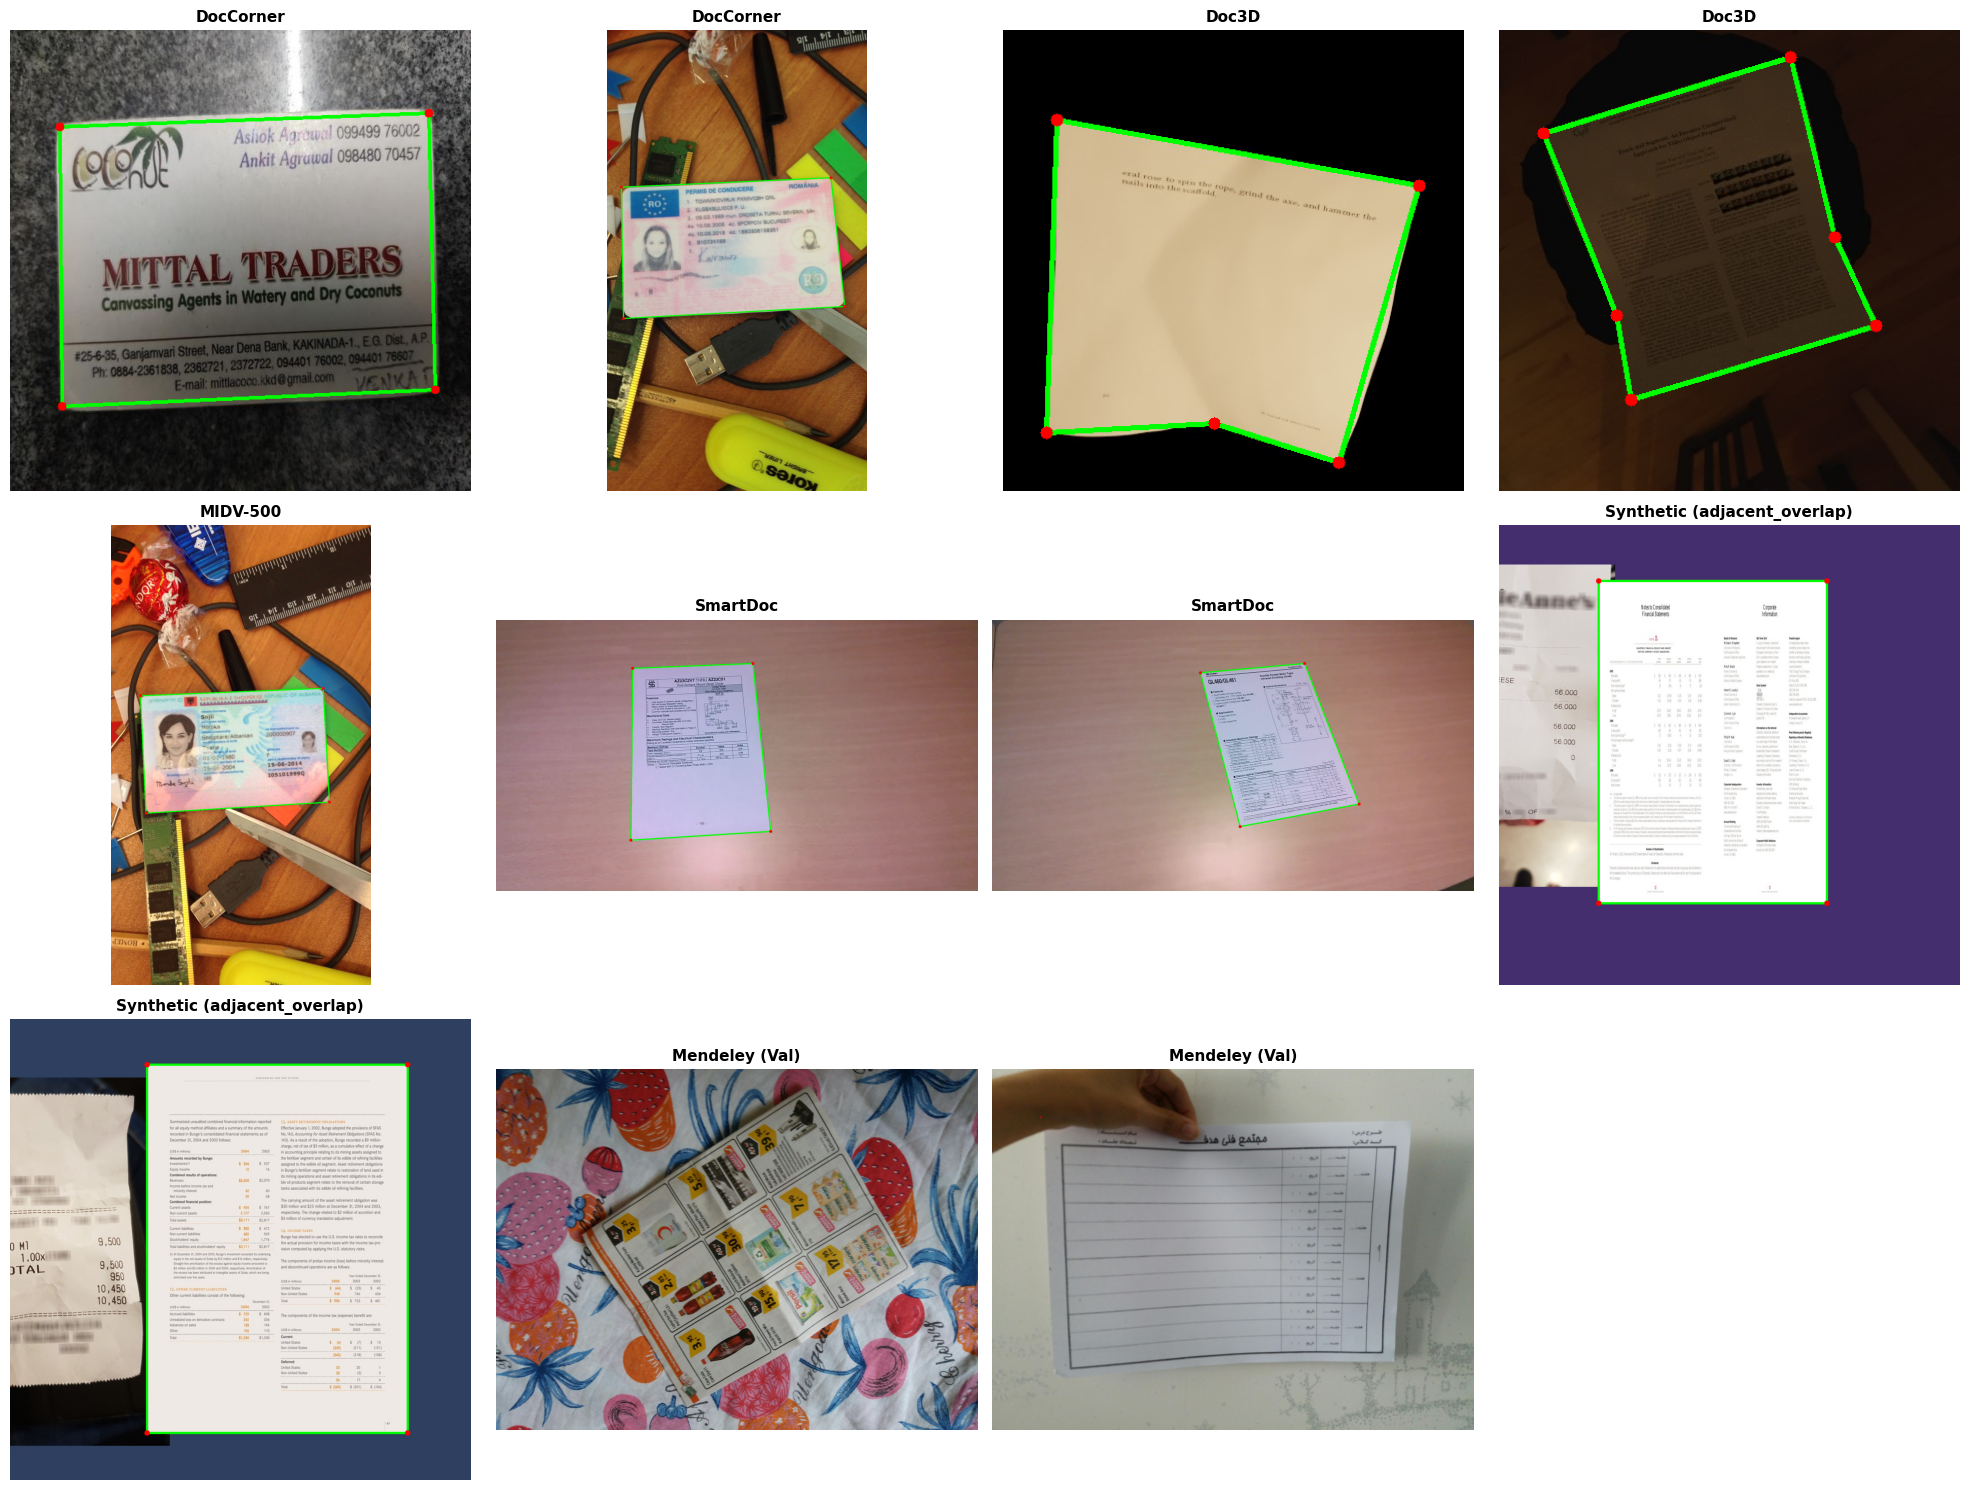

In [ ]:
# @title Cell 8: Inspect Raw Ground-Truth Annotations Across All Datasets
import os
import glob
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def draw_polygon_on_image(img, pts, color=(0, 255, 0), thickness=3):
    pts_arr = np.array(pts, dtype=np.int32).reshape((-1, 1, 2))
    cv2.polylines(img, [pts_arr], isClosed=True, color=color, thickness=thickness)
    for p in pts:
        cv2.circle(img, (int(p[0]), int(p[1])), radius=6, color=(255, 0, 0), thickness=-1)
    return img

preview_targets = []

# 1. DocCorner (Normalized [0, 1])
dc_json = "/content/raw_datasets/doc_corner/annotations.json"
if os.path.exists(dc_json):
    with open(dc_json) as f:
        dc_data = json.load(f)
    for k in list(dc_data.keys())[:2]:
        p = f"/content/raw_datasets/doc_corner/images/{k}"
        if os.path.exists(p):
            img = cv2.imread(p)
            h, w = img.shape[:2]
            abs_pts = [[pt[0] * w, pt[1] * h] for pt in dc_data[k]["corners"]]
            preview_targets.append(("DocCorner", draw_polygon_on_image(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), abs_pts)))

# 2. Doc3D (Mask Contours)
d3d_masks = glob.glob("/content/raw_datasets/doc3d/masks/*.png")[:2]
for mp in d3d_masks:
    base_name = os.path.splitext(os.path.basename(mp))[0]
    # Search for matching image with .jpg, .png, or .jpeg extension
    matching_imgs = glob.glob(f"/content/raw_datasets/doc3d/images/{base_name}.*")
    if matching_imgs:
        ip = matching_imgs[0]
        img = cv2.imread(ip)
        mask = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
        if img is not None and mask is not None:
            contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            if contours:
                largest = max(contours, key=cv2.contourArea)
                epsilon = 0.01 * cv2.arcLength(largest, True)
                approx = cv2.approxPolyDP(largest, epsilon, True)
                pts = [p[0] for p in approx]
                preview_targets.append(("Doc3D", draw_polygon_on_image(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), pts)))

# 3. MIDV-500 (Absolute Quads)
midv_tifs = glob.glob("/content/raw_datasets/midv500/**/*.tif", recursive=True)[:2]
for ip in midv_tifs:
    jp = ip.replace("/images/", "/ground_truth/").replace(".tif", ".json")
    if os.path.exists(jp):
        with open(jp) as f:
            jdata = json.load(f)
        quad = jdata.get("quad")
        if quad:
            img = cv2.imread(ip)
            if img is not None:
                preview_targets.append(("MIDV-500", draw_polygon_on_image(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), quad)))

# 4. SmartDoc 2015 (Absolute Quads)
sd_json = "/content/raw_datasets/smartdoc15/annotations.json"
if os.path.exists(sd_json):
    with open(sd_json) as f:
        sd_data = json.load(f)
    for k in list(sd_data.keys())[:2]:
        p = f"/content/raw_datasets/smartdoc15/images/{k}"
        if os.path.exists(p):
            img = cv2.imread(p)
            if img is not None:
                preview_targets.append(("SmartDoc", draw_polygon_on_image(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), sd_data[k]["corners"])))

# 5. Synthetic (Normalized [0, 1])
syn_json = "/content/raw_datasets/synthetic/annotations.json"
if os.path.exists(syn_json):
    with open(syn_json) as f:
        syn_data = json.load(f)
    for k in list(syn_data.keys())[:2]:
        p = f"/content/raw_datasets/synthetic/images/{k}"
        if os.path.exists(p):
            img = cv2.imread(p)
            if img is not None:
                h, w = img.shape[:2]
                abs_pts = [[pt[0] * w, pt[1] * h] for pt in syn_data[k]["corners"]]
                preview_targets.append((f"Synthetic ({syn_data[k].get('type', 'syn')})", draw_polygon_on_image(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), abs_pts)))

# 6. Mendeley Validation (CSV Coordinates)
mendeley_csvs = glob.glob("/content/raw_datasets/mendeley/**/*.csv", recursive=True)[:2]
for cp in mendeley_csvs:
    ip = cp.replace(".csv", ".jpg")
    if os.path.exists(ip):
        try:
            df = pd.read_csv(cp, header=None)
            raw_pts = df.values[:4, :2].astype(float)
            img = cv2.imread(ip)
            if img is not None:
                preview_targets.append(("Mendeley (Val)", draw_polygon_on_image(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), raw_pts)))
        except Exception:
            pass

# Plot samples in grid
if not preview_targets:
    print("❌ No images/annotations found to display. Check dataset directory paths.")
else:
    cols = 4
    rows = int(np.ceil(len(preview_targets) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(20, 5 * rows))

    if rows == 1 and cols == 1:
        axes = np.array([axes])
    axes = axes.flatten()

    for idx, (title, img) in enumerate(preview_targets):
        axes[idx].imshow(img)
        axes[idx].set_title(title, fontsize=11, fontweight="bold")
        axes[idx].axis("off")

    for idx in range(len(preview_targets), len(axes)):
        axes[idx].axis("off")

    plt.tight_layout()
    plt.show()

> **Modular Script Reference:** `data_prep/build_yolo_format.py` (`build_dataset()`, `write_yolo_label()`)

## 3. Master Assembly: Unified YOLOv8 Segmentation Dataset

YOLOv8-seg expects normalized polygon labels formatted as:
$$	ext{class\_id} \quad x_1 \quad y_1 \quad x_2 \quad y_2 \quad \dots \quad x_n \quad y_n$$
where coordinates are clamped to $[0.0, 1.0]$ relative to image dimensions:
- For standard quads, $N = 4$ vertices (8 coordinates).
- For curved Doc3D pages, $N \ge 3$ vertices tracing the page contour approximated by RDP (`cv2.approxPolyDP` with $\epsilon = 0.005 	imes 	ext{perimeter}$).
- Generates `dataset.yaml` with class `0: document` and points to `images/train`, `images/val`, `labels/train`, and `labels/val`.

In [ ]:
# @title Cell 9: Master Assembly of Unified YOLO-seg Training & Val Dataset
import os
import glob
import json
import cv2
import shutil
import pandas as pd
from tqdm.auto import tqdm

OUT_DIR = "/content/yolo_dataset"
os.makedirs(f"{OUT_DIR}/images/train", exist_ok=True)
os.makedirs(f"{OUT_DIR}/labels/train", exist_ok=True)
os.makedirs(f"{OUT_DIR}/images/val", exist_ok=True)
os.makedirs(f"{OUT_DIR}/labels/val", exist_ok=True)

def write_yolo_label(dst_lbl, coords, w=1, h=1, is_normalized=False):
    """Writes clamped polygon coordinates to a YOLO segmentation format text file."""
    flat_coords = []
    for pt in coords:
        x, y = float(pt[0]), float(pt[1])
        if not is_normalized:
            x, y = x / w, y / h
        flat_coords.append(f"{max(0.0, min(1.0, x)):.5f}")
        flat_coords.append(f"{max(0.0, min(1.0, y)):.5f}")

    with open(dst_lbl, "w") as f:
        f.write(f"0 {' '.join(flat_coords)}\n")

# ---------------------------------------------------------------------
# 1. DocCorner
# ---------------------------------------------------------------------
dc_json = "/content/raw_datasets/doc_corner/annotations.json"
if os.path.exists(dc_json):
    with open(dc_json) as f:
        dc_data = json.load(f)
    for img_name, data in tqdm(dc_data.items(), desc="1/7 DocCorner"):
        src_img = f"/content/raw_datasets/doc_corner/images/{img_name}"
        if os.path.exists(src_img):
            out_name = f"doccorner_{img_name}"
            shutil.copy(src_img, f"{OUT_DIR}/images/train/{out_name}")
            write_yolo_label(
                f"{OUT_DIR}/labels/train/{os.path.splitext(out_name)[0]}.txt",
                data["corners"],
                is_normalized=True
            )

# ---------------------------------------------------------------------
# 2. Doc3D
# ---------------------------------------------------------------------
d3d_masks = glob.glob("/content/raw_datasets/doc3d/masks/*.png")
for mask_p in tqdm(d3d_masks, desc="2/7 Doc3D"):
    base_id = os.path.splitext(os.path.basename(mask_p))[0]
    matching_imgs = glob.glob(f"/content/raw_datasets/doc3d/images/{base_id}.*")
    if matching_imgs:
        src_img = matching_imgs[0]
        mask = cv2.imread(mask_p, cv2.IMREAD_GRAYSCALE)
        if mask is not None:
            h, w = mask.shape[:2]
            contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            if contours:
                largest = max(contours, key=cv2.contourArea)
                # Fixed syntax error (added missing * operator)
                epsilon = 0.005 * cv2.arcLength(largest, True)
                approx = cv2.approxPolyDP(largest, epsilon, True)
                coords = [p[0] for p in approx]
                if len(coords) >= 3:
                    out_name = f"{base_id}.jpg" if not base_id.startswith("doc3d_") else f"{base_id}.jpg"
                    shutil.copy(src_img, f"{OUT_DIR}/images/train/{out_name}")
                    write_yolo_label(
                        f"{OUT_DIR}/labels/train/{os.path.splitext(out_name)[0]}.txt",
                        coords,
                        w,
                        h,
                        is_normalized=False
                    )

# ---------------------------------------------------------------------
# 3. MIDV-500
# ---------------------------------------------------------------------
midv_imgs = glob.glob("/content/raw_datasets/midv500/**/*.tif", recursive=True)
for src_img in tqdm(midv_imgs, desc="3/7 MIDV-500"):
    json_path = src_img.replace("/images/", "/ground_truth/").replace(".tif", ".json")
    if os.path.exists(json_path):
        with open(json_path) as f:
            jdata = json.load(f)
        quad = jdata.get("quad")
        if quad:
            img = cv2.imread(src_img)
            if img is not None:
                h, w = img.shape[:2]
                out_name = f"midv_{os.path.basename(src_img).replace('.tif', '.jpg')}"
                cv2.imwrite(f"{OUT_DIR}/images/train/{out_name}", img, [cv2.IMWRITE_JPEG_QUALITY, 92])
                write_yolo_label(
                    f"{OUT_DIR}/labels/train/{os.path.splitext(out_name)[0]}.txt",
                    quad,
                    w,
                    h,
                    is_normalized=False
                )

# ---------------------------------------------------------------------
# 4. SmartDoc 2015
# ---------------------------------------------------------------------
sd_json = "/content/raw_datasets/smartdoc15/annotations.json"
if os.path.exists(sd_json):
    with open(sd_json) as f:
        sd_data = json.load(f)
    for img_name, data in tqdm(sd_data.items(), desc="4/7 SmartDoc"):
        src_img = f"/content/raw_datasets/smartdoc15/images/{img_name}"
        if os.path.exists(src_img):
            out_name = f"smartdoc_{img_name}"
            shutil.copy(src_img, f"{OUT_DIR}/images/train/{out_name}")
            write_yolo_label(
                f"{OUT_DIR}/labels/train/{os.path.splitext(out_name)[0]}.txt",
                data["corners"],
                data["width"],
                data["height"],
                is_normalized=False
            )

# ---------------------------------------------------------------------
# 5. CORD-v2 (Full-Bleed Snapping)
# ---------------------------------------------------------------------
cord_imgs = glob.glob("/content/raw_datasets/cord/images/*.jpg")
for src_img in tqdm(cord_imgs, desc="5/7 CORD-v2"):
    img = cv2.imread(src_img)
    if img is not None:
        h, w = img.shape[:2]
        out_name = f"cord_{os.path.basename(src_img)}"
        shutil.copy(src_img, f"{OUT_DIR}/images/train/{out_name}")
        write_yolo_label(
            f"{OUT_DIR}/labels/train/{os.path.splitext(out_name)[0]}.txt",
            [[0, 0], [w, 0], [w, h], [0, h]],
            w,
            h,
            is_normalized=False
        )

# ---------------------------------------------------------------------
# 6. Synthetic Overlaps & Edge Cases
# ---------------------------------------------------------------------
syn_json = "/content/raw_datasets/synthetic/annotations.json"
if os.path.exists(syn_json):
    with open(syn_json) as f:
        syn_data = json.load(f)
    for img_name, data in tqdm(syn_data.items(), desc="6/7 Synthetic"):
        src_img = f"/content/raw_datasets/synthetic/images/{img_name}"
        if os.path.exists(src_img):
            out_name = f"synthetic_{img_name}"
            shutil.copy(src_img, f"{OUT_DIR}/images/train/{out_name}")
            write_yolo_label(
                f"{OUT_DIR}/labels/train/{os.path.splitext(out_name)[0]}.txt",
                data["corners"],
                is_normalized=True
            )

# ---------------------------------------------------------------------
# 7. Mendeley Validation Partition
# ---------------------------------------------------------------------
mendeley_csvs = glob.glob("/content/raw_datasets/mendeley/**/*.csv", recursive=True)
val_count = 0
for csv_path in tqdm(mendeley_csvs, desc="7/7 Mendeley (Val)"):
    img_path = csv_path.replace(".csv", ".jpg")
    if os.path.exists(img_path):
        img = cv2.imread(img_path)
        if img is not None:
            try:
                df = pd.read_csv(csv_path, header=None)
                raw_coords = df.values[:4, :2].astype(float)
                h, w = img.shape[:2]
                out_name = f"mendeley_{val_count:05d}"
                cv2.imwrite(f"{OUT_DIR}/images/val/{out_name}.jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 90])
                write_yolo_label(
                    f"{OUT_DIR}/labels/val/{out_name}.txt",
                    raw_coords,
                    w,
                    h,
                    is_normalized=False
                )
                val_count += 1
            except Exception:
                continue

# ---------------------------------------------------------------------
# Generate dataset.yaml Configuration
# ---------------------------------------------------------------------
yaml_content = f"""path: {OUT_DIR}
train: images/train
val: images/val

names:
  0: document
"""
with open(f"{OUT_DIR}/dataset.yaml", "w") as f:
    f.write(yaml_content.strip())

train_total = len(glob.glob(f"{OUT_DIR}/images/train/*"))
val_total = len(glob.glob(f"{OUT_DIR}/images/val/*"))

print("=" * 50)
print("✅ UNIFIED YOLO DATASET GENERATION COMPLETE!")
print(f"📁 Training Images:   {train_total}")
print(f"📁 Validation Images: {val_total}")
print(f"⚙️ Config Location:   {OUT_DIR}/dataset.yaml")
print("=" * 50)

1/7 DocCorner:   0%|          | 0/2000 [00:00<?, ?it/s]

2/7 Doc3D:   0%|          | 0/1500 [00:00<?, ?it/s]

3/7 MIDV-500:   0%|          | 0/301 [00:00<?, ?it/s]

4/7 SmartDoc:   0%|          | 0/150 [00:00<?, ?it/s]

5/7 CORD-v2:   0%|          | 0/800 [00:00<?, ?it/s]

6/7 Synthetic:   0%|          | 0/1300 [00:00<?, ?it/s]

7/7 Mendeley (Val):   0%|          | 0/1108 [00:00<?, ?it/s]

✅ UNIFIED YOLO DATASET GENERATION COMPLETE!
📁 Training Images:   6050
📁 Validation Images: 1094
⚙️ Config Location:   /content/yolo_dataset/dataset.yaml


> **Modular Script Reference:** `data_prep/build_yolo_format.py` (`_build_mendeley_val()`)

### 3.1 Mendeley Validation Label Alignment & Reshape Fix

Mendeley CSV annotations exhibit shape inconsistencies across raw folders (some stored as $1 	imes 8$ flat vectors, others as $4 	imes 2$ coordinate pairs). This step flattens and reshapes the raw CSV inputs into 4 discrete $[x, y]$ pairs, synchronizes file names with image frames, and writes valid 9-token YOLO segmentation labels.

In [ ]:
# @title Fix Mendeley Validation Labels
import os
import glob
import cv2
import pandas as pd
from tqdm.auto import tqdm

OUT_DIR = "/content/yolo_dataset"

# Use sorted() to guarantee image/label alignment matches perfectly
mendeley_csvs = sorted(glob.glob("/content/raw_datasets/mendeley/**/*.csv", recursive=True))
val_count = 0

print("🔧 Fixing Mendeley Validation Labels...")
for csv_path in tqdm(mendeley_csvs, desc="Rebuilding Val Set"):
    img_path = csv_path.replace(".csv", ".jpg")
    if os.path.exists(img_path):
        img = cv2.imread(img_path)
        if img is not None:
            try:
                df = pd.read_csv(csv_path, header=None)

                # ROBUST PARSING: Flatten the CSV values regardless of shape (1x8 or 4x2)
                vals = df.values.flatten()
                if len(vals) < 8:
                    continue

                # Reshape the first 8 values into 4 discrete [x, y] coordinate pairs
                raw_coords = vals[:8].reshape(4, 2).astype(float)

                h, w = img.shape[:2]
                out_name = f"mendeley_{val_count:05d}"

                # Overwrite image and label to guarantee they are 100% synced
                cv2.imwrite(f"{OUT_DIR}/images/val/{out_name}.jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 90])

                flat_coords = []
                for pt in raw_coords:
                    x, y = float(pt[0]) / w, float(pt[1]) / h
                    flat_coords.append(f"{max(0.0, min(1.0, x)):.5f}")
                    flat_coords.append(f"{max(0.0, min(1.0, y)):.5f}")

                with open(f"{OUT_DIR}/labels/val/{out_name}.txt", "w") as f:
                    f.write(f"0 {' '.join(flat_coords)}\n")

                val_count += 1
            except Exception:
                continue

print(f"✅ Fixed {val_count} Mendeley labels (9 columns generated for segmentation).")

🔧 Fixing Mendeley Validation Labels...


Rebuilding Val Set:   0%|          | 0/1108 [00:00<?, ?it/s]

✅ Fixed 1094 Mendeley labels (9 columns generated for segmentation).


> **Modular Script Reference:** `training/train.py` (`run_training()`)

## 4. Model Training: YOLOv8-Seg Configuration & Edge Optimization

We train `yolov8n-seg.pt` (Nano Segmentation), designed for high-accuracy edge deployment:
- **Architecture Choice:** YOLOv8n-seg has only ~3.4M parameters, making it fast enough for real-time mobile inference ($> 30	ext{ FPS}$) while generating high-resolution prototype segmentation masks.
- **Image Resolution (`imgsz=640`):** Standard 640px square resolution preserves fine page corners while keeping mobile NPU memory footprints minimal.
- **Batch Size (`batch=16`) & Precision (`amp=True`):** Balances GPU memory consumption with gradient estimation stability, leveraging FP16 mixed precision.
- **Early Stopping (`patience=15`):** Stops training when validation mAP stops improving for 15 epochs, preventing overfitting on synthetic textures.

In [ ]:
# @title Train YOLOv8-Seg and Export for Android (TFLite)
# 1. Install the Ultralytics YOLO framework
!pip install -q ultralytics

from ultralytics import YOLO
import os

# Define the path to the dataset configuration generated in the previous step
yaml_path = "/content/yolo_dataset/dataset.yaml"
if not os.path.exists(yaml_path):
    raise FileNotFoundError(f"Cannot find {yaml_path}. Run the Master Assembly cell first.")

# 2. Initialize the YOLOv8 Nano Segmentation model (Best for Android/Mobile)
print("🚀 Initializing YOLOv8n-seg...")
model = YOLO("yolov8n-seg.pt")

# 3. Train the model
# Adjust 'epochs' higher (e.g., 100) if the model is underfitting, or lower if overfitting.
print("🔥 Starting Training...")
results = model.train(
    data=yaml_path,
    epochs=50,           # Number of training loops
    imgsz=640,           # Standard resolution for mobile document scanning
    batch=16,            # Number of images per batch (adjust based on Colab GPU RAM)
    patience=15,         # Stop early if no improvement for 15 epochs
    project="DocScan",   # Output folder name
    name="android_model",# Run name
    device=0             # Use Colab GPU
)

# 4. Export the trained model to Android-compatible formats
print("📦 Exporting model for Android (TensorFlow Lite)...")

# Export to standard TFLite (FP16 precision - good balance of speed/accuracy)
model.export(format="tflite", imgsz=640)

# Export to quantized TFLite (INT8 precision - maximum speed for low-end Android devices)
model.export(format="tflite", int8=True, imgsz=640)

print("=" * 50)
print("✅ Training and Export Complete!")
print("📁 Find your Android .tflite models in: /content/DocScan/android_model/weights/")
print("=" * 50)

🚀 Initializing YOLOv8n-seg...
🔥 Starting Training...
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, na

/usr/local/lib/python3.13/dist-packages/torchao/quantization/quant_api.py:1558: SyntaxWarning: invalid escape sequence '\.'
  * regex for parameter names, must start with `re:`, e.g. `re:language\.layers\..+\.q_proj.weight`.
W1108 13:12:18.193000 518 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.



LiteRT: starting export with litert_torch 0.10.0...


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:02) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

... (45 outputs left out)

(00:00) [ DONE] Write Model to /content/runs/segment/DocScan/android_model-2/weights/best_int8.tflite (+00:00)

LiteRT: applying static quantization (int8 weights + int8 activations)...


/usr/local/lib/python3.13/dist-packages/ai_edge_litert/interpreter.py:480: UserWarning: Warning: Enabling `experimental_preserve_all_tensors` with the BUILTIN or AUTO op resolver is intended for debugging purposes only. Be aware that this can significantly increase memory usage by storing all intermediate tensors. If you encounter memory problems or are not actively debugging, consider disabling this option.
  warnings.warn(
Applying Transformations to tensors:: 100%|██████████| 481/481 [00:00<00:00, 17677.17it/s]


Model name: /content/runs/segment/DocScan/android_model-2/weights/best_int8.tflite
Original model size: 13.16 MiB
Quantized model size: 3.58 MiB
Quantization Ratio: 0.27 (3.7x smaller)
Total time: 201.17 ms
LiteRT: export success ✅ 12.7s, saved as '/content/runs/segment/DocScan/android_model-2/weights/best_int8.tflite' (3.6 MB)

Export complete (13.0s)
Results saved to /content/runs/segment/DocScan/android_model-2/weights/best_int8.tflite
Predict:         yolo predict task=segment model=/content/runs/segment/DocScan/android_model-2/weights/best_int8.tflite imgsz=640 
Validate:        yolo val task=segment model=/content/runs/segment/DocScan/android_model-2/weights/best_int8.tflite imgsz=640 data=/content/yolo_dataset/dataset.yaml 
Visualize:       https://netron.app
✅ Training and Export Complete!
📁 Find your Android .tflite models in: /content/DocScan/android_model/weights/


> **Modular Script Reference:** `src/export.py` (`export_tflite()`)

## 5. Standalone Model Export to Android TFLite

Converts the trained PyTorch checkpoint (`best.pt`) into production-ready edge formats:
1. **FP16 Precision (`best.tflite`):** Half-precision floating point. Yields $2	imes$ model compression (~6.8 MB) with negligible loss in corner localization accuracy. Recommended for mid-range and high-end Android devices.
2. **INT8 Quantization (`best_int8.tflite`):** Full 8-bit integer quantization using representative calibration data. Maximizes inference throughput and minimizes battery consumption on budget Android chipsets (Snapdragon, MediaTek) equipped with fixed-point DSPs.

In [ ]:
# @title Export Saved Model to Android TFLite
from ultralytics import YOLO

# Load the highest-performing checkpoint from the completed run
model = YOLO("/content/runs/segment/DocScan/android_model-2/weights/best.pt")

print("📦 Exporting best model for Android (TensorFlow Lite)...")

# 1. FP16 Precision (Standard balance of mobile speed and edge accuracy)
model.export(format="tflite", imgsz=640)

# 2. INT8 Precision (Fastest inference, optimized for low/mid-range Android chipsets)
model.export(format="tflite", int8=True, imgsz=640)

print("✅ Export Complete! Find your .tflite files in:")
print("/content/runs/segment/DocScan/android_model-2/weights/")

📦 Exporting best model for Android (TensorFlow Lite)...
WARNING ⚠️ format='tflite' is deprecated as of 8.4.83 and has been replaced by the unified Google LiteRT format. Exporting format='litert' instead. See https://docs.ultralytics.com/integrations/litert
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLOv8n-seg summary (fused): 86 layers, 3,385,123 parameters, 0 gradients, 11.9 GFLOPs

PyTorch: starting from '/content/runs/segment/DocScan/android_model-2/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) ((1, 37, 8400), (1, 32, 160, 160)) (6.7 MB)

LiteRT: starting export with litert_torch 0.10.0...


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:01) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

(00:02) [ DONE] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions (+00:01)

(00:02) [ DONE] LiteRT-Torch Convert > Torch Export: serving_default (+00:02)

... (43 outputs left out)

(00:00) [ DONE] Write Model to /content/runs/segment/DocScan/android_model-2/weights/best_int8.tflite (+00:00)

LiteRT: applying static quantization (int8 weights + int8 activations)...


/usr/local/lib/python3.13/dist-packages/ai_edge_litert/interpreter.py:480: UserWarning: Warning: Enabling `experimental_preserve_all_tensors` with the BUILTIN or AUTO op resolver is intended for debugging purposes only. Be aware that this can significantly increase memory usage by storing all intermediate tensors. If you encounter memory problems or are not actively debugging, consider disabling this option.
  warnings.warn(
Applying Transformations to tensors:: 100%|██████████| 481/481 [00:00<00:00, 26062.35it/s]


Model name: /content/runs/segment/DocScan/android_model-2/weights/best_int8.tflite
Original model size: 13.16 MiB
Quantized model size: 3.58 MiB
Quantization Ratio: 0.27 (3.7x smaller)
Total time: 201.53 ms
LiteRT: export success ✅ 13.1s, saved as '/content/runs/segment/DocScan/android_model-2/weights/best_int8.tflite' (3.6 MB)

Export complete (13.4s)
Results saved to /content/runs/segment/DocScan/android_model-2/weights/best_int8.tflite
Predict:         yolo predict task=segment model=/content/runs/segment/DocScan/android_model-2/weights/best_int8.tflite imgsz=640 
Validate:        yolo val task=segment model=/content/runs/segment/DocScan/android_model-2/weights/best_int8.tflite imgsz=640 data=/content/yolo_dataset/dataset.yaml 
Visualize:       https://netron.app
✅ Export Complete! Find your .tflite files in:
/content/runs/segment/DocScan/android_model-2/weights/


> **Modular Script Reference:** `training/test.py` (`run_evaluation()`) & `src/postprocess.py` (`get_strict_4_corners()`, `sort_4_corners()`, `perspective_warp()`)

## 6. Evaluation & Geometric Post-Processing: Strict 4-Corner Extraction

### Validation Metrics & Mathematical Post-Processing Pipeline
Raw YOLOv8 segmentation masks output arbitrary polygons with 10–200 vertices. Document rectifiers (e.g. OpenCV, Android ML Kit) require **strictly 4 ordered corners**:

```
Raw Mask Polygon (N vertices)
         │
         ▼
cv2.convexHull()            ── Bridges concave dips caused by thumb occlusions & edge noise
         │
         ▼
Adaptive approxPolyDP sweep ── Sweeps ε ∈ [0.01, 0.10] × perimeter to isolate exactly 4 vertices
         │
         ▼
sort_4_corners()            ── Orders points canonically: [TL, TR, BR, BL]
         │
         ▼
cv2.warpPerspective()       ── Applies homography transform M to produce orthogonal scan
```

#### Canonical Corner Sorting Logic:
1. **Top-Left (TL):** Point minimizing the sum: $rg\min(x + y)$
2. **Bottom-Right (BR):** Point maximizing the sum: $rg\max(x + y)$
3. **Top-Right (TR):** Point minimizing the difference: $rg\min(x - y)$
4. **Bottom-Left (BL):** Point maximizing the difference: $rg\max(x - y)$

In [68]:
# @title Setup Model, Evaluate Metrics & Define Post-Processing
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random
from ultralytics import YOLO

# 1. Locate the best model weights
weights_path = "/content/runs/segment/DocScan/android_model-2/weights/best.pt"
if not os.path.exists(weights_path):
    alt_paths = sorted(glob.glob("/content/runs/segment/**/weights/best.pt", recursive=True))
    if alt_paths:
        weights_path = alt_paths[-1]
    else:
        raise FileNotFoundError("Could not find best.pt. Check your training directory path.")

print(f"📦 Loading weights from: {weights_path}")
model = YOLO(weights_path)

# 2. Run Validation Metrics Check
print("\n📊 Computing final validation performance...")
metrics = model.val(data="/content/yolo_dataset/dataset.yaml", split="val", imgsz=640)
print(f"   -> Mask mAP50:    {metrics.seg.map50:.4f}")
print(f"   -> Mask mAP50-95: {metrics.seg.map:.4f}")
print(f"   -> Box mAP50:     {metrics.box.map50:.4f}")
print(f"   -> Box mAP50-95:  {metrics.box.map:.4f}")

# 3. Define strict 4-corner extraction (Replacing raw approxPolyDP)
def sort_4_corners(pts):
    pts = pts.reshape(-1, 2)
    rect = np.zeros((4, 2), dtype="float32")
    s = pts.sum(axis=1)
    diff = np.diff(pts, axis=1)
    rect[0] = pts[np.argmin(s)]       # TL
    rect[2] = pts[np.argmax(s)]       # BR
    rect[1] = pts[np.argmin(diff)]    # TR
    rect[3] = pts[np.argmax(diff)]    # BL
    return rect

def get_strict_4_corners(pts):
    hull = cv2.convexHull(pts)
    perimeter = cv2.arcLength(hull, True)
    for eps_factor in np.linspace(0.01, 0.10, 90):
        approx = cv2.approxPolyDP(hull, eps_factor * perimeter, True)
        if len(approx) == 4:
            return sort_4_corners(approx)
    return sort_4_corners(hull)

# 4. Prepare dataset image pool
val_images = sorted(glob.glob("/content/yolo_dataset/images/val/*.jpg"))
if not val_images:
    raise FileNotFoundError("No validation images found in /content/yolo_dataset/images/val/")
print(f"\n✅ Setup complete. {len(val_images)} validation images ready for testing.")

📦 Loading weights from: /content/runs/segment/DocScan/android_model-2/weights/best.pt

📊 Computing final validation performance...
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 86 layers, 3,385,123 parameters, 0 gradients, 11.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2965.4±302.6 MB/s, size: 1651.3 KB)
val: Scanning /content/yolo_dataset/labels/val.cache... 1094 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1094/1094 208.6Mit/s 0.0s


/usr/lib/python3.13/multiprocessing/popen_fork.py:73: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 69/69 1.3s/it 1:28
                   all       1094       1094       0.92      0.889      0.927      0.802      0.894      0.879      0.895      0.772
Speed: 1.5ms preprocess, 5.0ms inference, 0.0ms loss, 3.0ms postprocess per image
Results saved to /content/runs/segment/val-3
   -> Mask mAP50:    0.8953
   -> Mask mAP50-95: 0.7715
   -> Box mAP50:     0.9273
   -> Box mAP50-95:  0.8019

✅ Setup complete. 1094 validation images ready for testing.


> **Modular Script Reference:** `src/infer.py` (`run_inference()`)

### 6.1 Qualitative Prediction Visualizations

Runs inference on held-out validation samples. Demonstrates how the adaptive convex hull and 4-corner extraction accurately bound the document, rendering:
- A semi-transparent green mask fill (`cv2.fillPoly`).
- Straight green boundary edges (`cv2.polylines`).
- Distinct corner anchors (`cv2.circle`) ready for perspective correction.

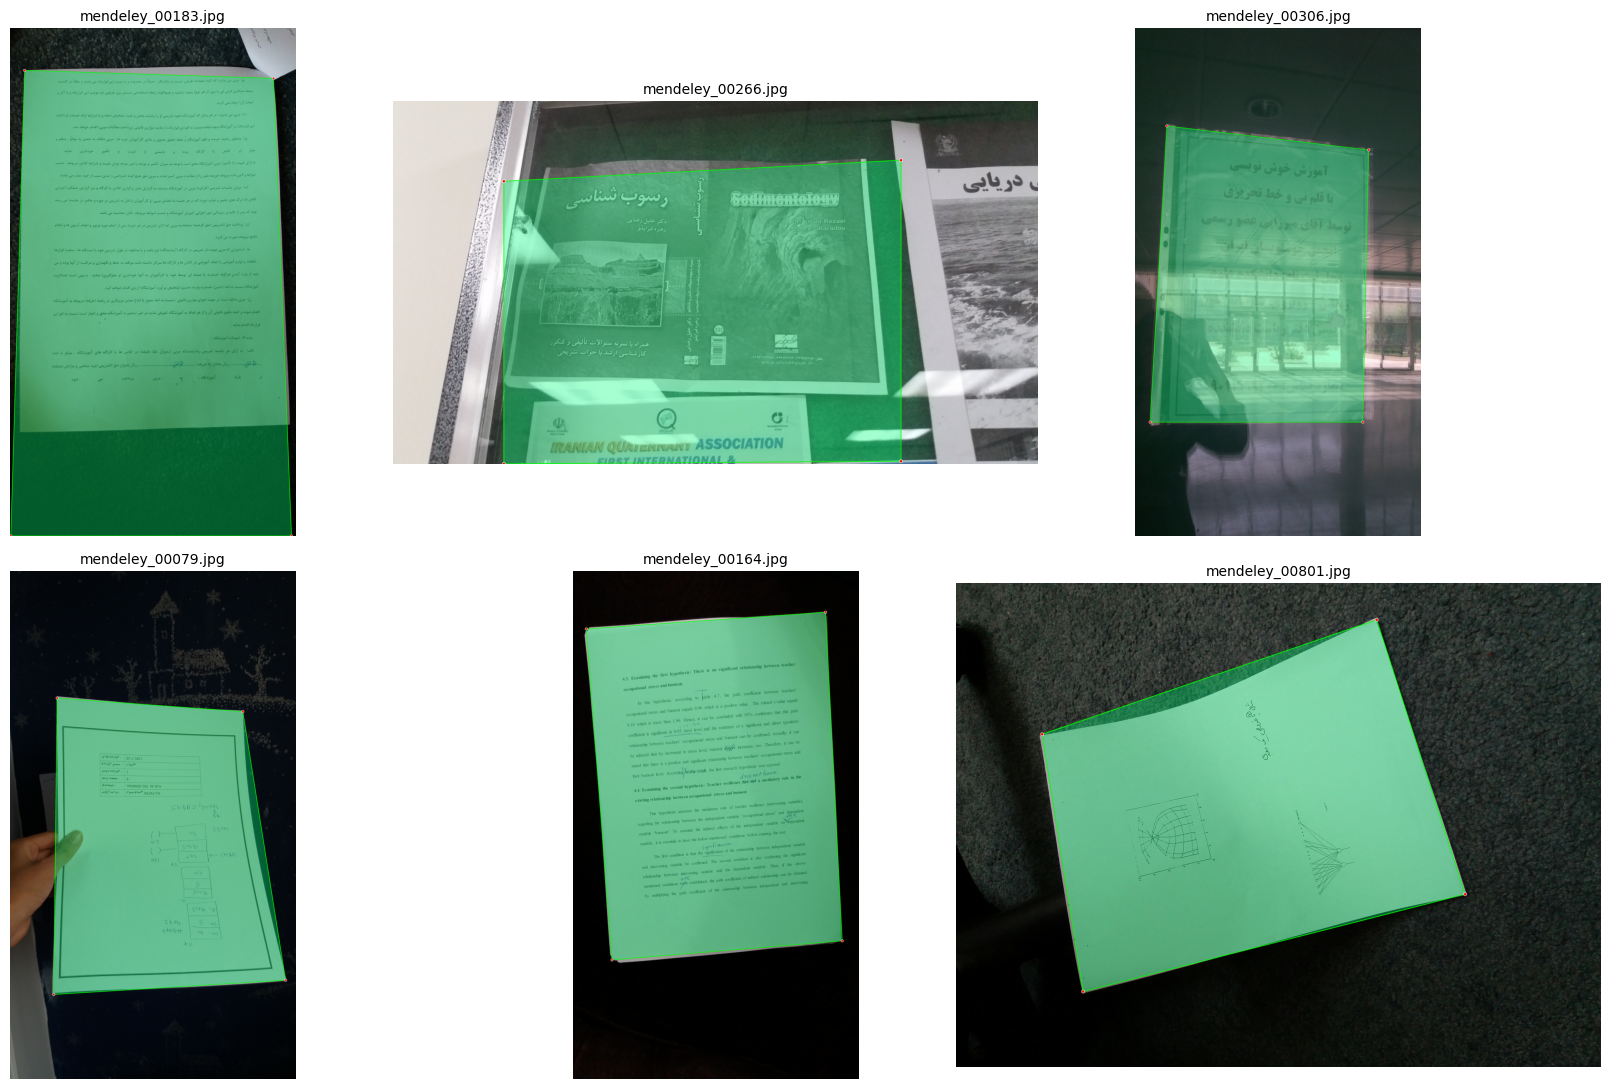

In [73]:
# @title Visualize Predictions (Run Multiple Times)
# Select 6 random validation images dynamically (no fixed seed)
sample_imgs = random.sample(val_images, min(6, len(val_images)))

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for idx, img_path in enumerate(sample_imgs):
    # Run high-res segmentation inference
    results = model.predict(source=img_path, imgsz=640, conf=0.25, retina_masks=True, verbose=False)[0]

    orig_bgr = cv2.imread(img_path)
    img_disp = cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2RGB)

    if results.masks is not None and len(results.masks.xy) > 0:
        # Find the largest page mask
        valid_masks = [m for m in results.masks.xy if len(m) >= 4]
        if valid_masks:
            largest_seg = max(valid_masks, key=lambda m: cv2.contourArea(m.astype(np.int32)))
            pts = largest_seg.astype(np.int32).reshape((-1, 1, 2))

            # Extract strictly 4 corners
            four_corners = get_strict_4_corners(pts).astype(np.int32)
            quad_pts = four_corners.reshape((-1, 1, 2))

            # Draw semi-transparent green mask fill using straight edges
            overlay = img_disp.copy()
            cv2.fillPoly(overlay, [quad_pts], (0, 255, 120))
            cv2.addWeighted(overlay, 0.35, img_disp, 0.65, 0, img_disp)

            # Draw straight boundary lines
            cv2.polylines(img_disp, [quad_pts], isClosed=True, color=(0, 255, 0), thickness=3)

            # Draw the 4 corner anchors
            for (cx, cy) in four_corners:
                cv2.circle(img_disp, (int(cx), int(cy)), radius=8, color=(255, 0, 0), thickness=-1)
                cv2.circle(img_disp, (int(cx), int(cy)), radius=10, color=(255, 255, 255), thickness=2)

    axes[idx].imshow(img_disp)
    axes[idx].set_title(os.path.basename(img_path), fontsize=10)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

> **Modular Script Reference:** `src/infer.py` & `src/webcam.py`

## 7. Real-Time Inference: In-Browser Single-Frame Capture Bridge

Implements a browser-to-Python bridge using Google Colab's JavaScript evaluation engine:
- Connects to your local webcam via `navigator.mediaDevices.getUserMedia`.
- Captures an in-browser frame and streams base64-encoded bytes to the Python runtime.
- Runs YOLOv8-seg prediction and displays the annotated result with detected corners.

📷 Initializing webcam interface. Click 'Capture Document' below when ready:


<IPython.core.display.Javascript object>


✅ Document detected successfully! Showing result:


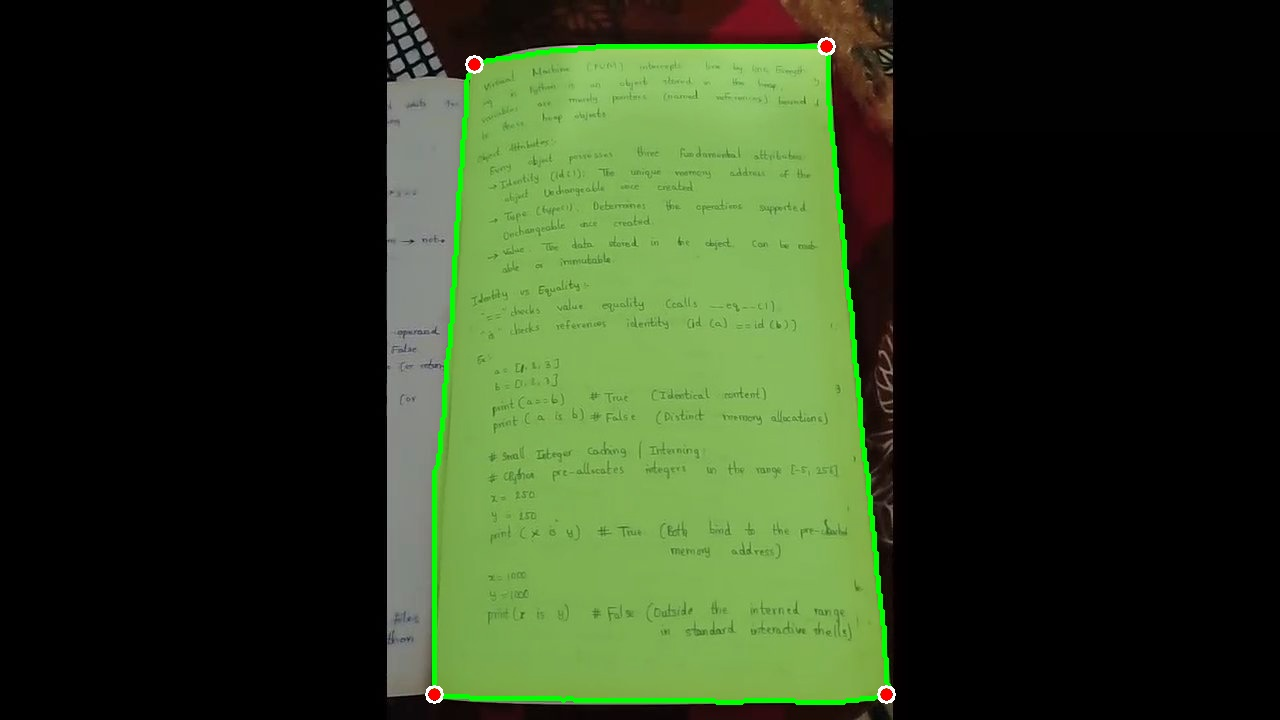

In [ ]:
# @title Live Webcam Testing with YOLOv8-Seg (In-Browser Colab Stream)
from IPython.display import display, Javascript, Image
from google.colab.output import eval_js
from base64 import b64decode, b64encode
import cv2
import numpy as np
import io
from PIL import Image as PILImage
from ultralytics import YOLO

# 1. Load the trained best model
weights_path = "/content/runs/segment/DocScan/android_model-2/weights/best.pt"
model = YOLO(weights_path)

# JavaScript helper to capture an image directly from your PC webcam
def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture Document';
      capture.style.padding = '8px 16px';
      capture.style.margin = '10px 0';
      capture.style.backgroundColor = '#007bff';
      capture.style.color = '#fff';
      capture.style.border = 'none';
      capture.style.borderRadius = '4px';
      capture.style.cursor = 'pointer';

      const video = document.createElement('video');
      video.style.display = 'block';
      video.style.borderRadius = '6px';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      div.appendChild(capture);
      video.srcObject = stream;
      await video.play();

      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
  ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

print("📷 Initializing webcam interface. Click 'Capture Document' below when ready:")
photo_file = take_photo('live_test.jpg')

# 2. Run inference on the captured image
img = cv2.imread(photo_file)
results = model.predict(source=img, imgsz=640, conf=0.25, verbose=False)[0]

# 3. Draw segmented boundaries and corner points
if results.masks is not None:
    for seg_coords in results.masks.xy:
        pts = seg_coords.astype(np.int32).reshape((-1, 1, 2))

        # Semi-transparent mask overlay
        overlay = img.copy()
        cv2.fillPoly(overlay, [pts], (0, 255, 120))
        cv2.addWeighted(overlay, 0.35, img, 0.65, 0, img)

        # Polygon boundary line
        cv2.polylines(img, [pts], isClosed=True, color=(0, 255, 0), thickness=3)

        # Detect and mark corner points
        perimeter = cv2.arcLength(pts, True)
        approx = cv2.approxPolyDP(pts, 0.02 * perimeter, True)
        for corner in approx:
            cx, cy = int(corner[0][0]), int(corner[0][1])
            cv2.circle(img, (cx, cy), radius=6, color=(0, 0, 255), thickness=-1)
            cv2.circle(img, (cx, cy), radius=8, color=(255, 255, 255), thickness=2)

    cv2.imwrite('live_test_pred.jpg', img)
    print("\n✅ Document detected successfully! Showing result:")
    display(Image('live_test_pred.jpg'))
else:
    print("\n⚠️ No document detected in view. Try adjusting distance or lighting.")
    display(Image(photo_file))

> **Modular Script Reference:** `src/webcam.py` (Local OpenCV implementation with `cv2.VideoCapture(0)`)

### 7.1 High-FPS Real-Time Webcam Stream with Hardware-Accelerated Overlay

An optimized asynchronous streaming architecture for real-time document tracking:
- **Dual-Canvas Architecture:** A visible high-resolution overlay canvas renders bounding quads at 60 FPS, while an offscreen hidden canvas downsizes frames to $416 	imes 312$ for low-latency transmission.
- **Half-Precision CUDA Inference:** The model is warmed up and evaluated in `fp16` mode on GPU, processing frames at high inference rates.
- **EMA Corner Smoothing:** Exponential moving average ($0.55 	imes 	ext{target} + 0.45 	imes 	ext{current}$) prevents jitter between frames, providing steady tracking of document corners.

In [67]:
# @title Ultra-Smooth High-FPS Live WebCam with Working Canvas Overlay
from IPython.display import display, HTML
from google.colab.output import register_callback
from IPython.display import JSON
from base64 import b64decode
import cv2
import numpy as np
import torch
from ultralytics import YOLO

# 1. Load trained YOLO model
weights_path = "/content/runs/segment/DocScan/android_model-2/weights/best.pt"
model = YOLO(weights_path)

# Optimize model for CUDA inference using 'fp16' quantization
if torch.cuda.is_available():
    model.to("cuda")
    # Warmup pass
    dummy = np.zeros((416, 416, 3), dtype=np.uint8)
    model.predict(source=dummy, imgsz=416, quantize='fp16', device=0, verbose=False)

def sort_4_corners(pts):
    pts = pts.reshape(-1, 2)
    rect = np.zeros((4, 2), dtype="float32")
    s = pts.sum(axis=1)
    diff = np.diff(pts, axis=1)
    rect[0] = pts[np.argmin(s)]       # Top-Left
    rect[2] = pts[np.argmax(s)]       # Bottom-Right
    rect[1] = pts[np.argmin(diff)]    # Top-Right
    rect[3] = pts[np.argmax(diff)]    # Bottom-Left
    return rect

def get_strict_4_corners(pts):
    hull = cv2.convexHull(pts)
    perimeter = cv2.arcLength(hull, True)
    for eps_factor in (0.02, 0.035, 0.05, 0.07):
        approx = cv2.approxPolyDP(hull, eps_factor * perimeter, True)
        if len(approx) == 4:
            return sort_4_corners(approx)
    return sort_4_corners(hull)

def process_frame(data_url):
    """Zero-overhead inference pipeline."""
    try:
        header, encoded = data_url.split(",", 1)
        frame_bytes = b64decode(encoded)
        img = cv2.imdecode(np.frombuffer(frame_bytes, np.uint8), cv2.IMREAD_COLOR)
        if img is None:
            return JSON({"found": False})

        h, w = img.shape[:2]

        # Use quantize='fp16' for warning-free half-precision inference
        results = model.predict(
            source=img,
            imgsz=416,
            conf=0.25,
            quantize='fp16',
            device=0 if torch.cuda.is_available() else "cpu",
            retina_masks=False,
            verbose=False
        )[0]

        if results.masks is not None and len(results.masks.xy) > 0:
            valid_masks = []
            min_area = w * h * 0.07
            for poly in results.masks.xy:
                if len(poly) >= 4:
                    cnt = poly.astype(np.int32)
                    area = cv2.contourArea(cnt)
                    if area > min_area:
                        valid_masks.append((cnt, area))

            if valid_masks:
                primary = max(valid_masks, key=lambda x: x[1])[0]
                four_corners = get_strict_4_corners(primary)
                norm_pts = [[float(p[0] / w), float(p[1] / h)] for p in four_corners]
                return JSON({"found": True, "corners": norm_pts})

    except Exception as e:
        return JSON({"found": False, "error": str(e)})

    return JSON({"found": False})

register_callback('notebook.process_frame', process_frame)

# 2. In-Browser 60 FPS Accelerated Display with Real-time FPS Meter
display(HTML('''
<div style="position: relative; width: 640px; height: 480px; margin: 0 auto; border-radius: 8px; overflow: hidden; background: #0b0c10; box-shadow: 0 4px 20px rgba(0,0,0,0.5);">
    <video id="webcam" width="640" height="480" autoplay playsinline muted style="position: absolute; left: 0; top: 0; width: 640px; height: 480px; object-fit: cover;"></video>
    <canvas id="overlay" width="640" height="480" style="position: absolute; left: 0; top: 0; width: 640px; height: 480px; pointer-events: none; z-index: 10;"></canvas>
    <canvas id="hidden_canvas" width="416" height="312" style="display: none;"></canvas>

    <div style="position: absolute; top: 12px; left: 12px; z-index: 20; display: flex; gap: 8px;">
        <span id="status_pill" style="padding: 4px 10px; background: rgba(0,0,0,0.7); color: #f1c40f; border-radius: 4px; font-family: monospace; font-size: 11px;">Initializing...</span>
        <span id="fps_meter" style="padding: 4px 8px; background: rgba(0,0,0,0.7); color: #00e5ff; border-radius: 4px; font-family: monospace; font-size: 11px;">0 INF/s</span>
    </div>

    <button id="toggleBtn" style="position: absolute; bottom: 12px; left: 12px; z-index: 20; padding: 6px 14px; background: #e74c3c; color: #fff; border: none; border-radius: 4px; font-weight: bold; cursor: pointer;">Stop Stream</button>
</div>

<script>
(async () => {
    const video = document.getElementById('webcam');
    const overlay = document.getElementById('overlay');
    const hiddenCanvas = document.getElementById('hidden_canvas');
    const statusPill = document.getElementById('status_pill');
    const fpsMeter = document.getElementById('fps_meter');
    const ctx = overlay.getContext('2d');
    const hiddenCtx = hiddenCanvas.getContext('2d');
    const toggleBtn = document.getElementById('toggleBtn');

    let active = true;
    let isProcessing = false;
    let targetCorners = null;

    let infCount = 0;
    let lastFpsTime = performance.now();

    toggleBtn.onclick = () => {
        active = !active;
        if (!active) {
            if (video.srcObject) video.srcObject.getVideoTracks()[0].stop();
            toggleBtn.textContent = 'Stream Stopped';
            toggleBtn.style.background = '#7f8c8d';
            statusPill.textContent = 'Offline';
            fpsMeter.textContent = '--';
            ctx.clearRect(0, 0, overlay.width, overlay.height);
        }
    };

    const stream = await navigator.mediaDevices.getUserMedia({
        video: { width: { ideal: 640 }, height: { ideal: 480 }, frameRate: { ideal: 30 } }
    });
    video.srcObject = stream;

    async function inferenceLoop() {
        if (!active) return;

        if (!isProcessing && video.readyState >= 2) {
            isProcessing = true;
            hiddenCtx.drawImage(video, 0, 0, 416, 312);
            const dataUrl = hiddenCanvas.toDataURL('image/jpeg', 0.55);

            google.colab.kernel.invokeFunction('notebook.process_frame', [dataUrl], {})
                .then(response => {
                    const res = response.data['application/json'];
                    if (res && res.found) {
                        targetCorners = res.corners;
                        statusPill.textContent = 'Tracking Locked';
                        statusPill.style.color = '#2ecc71';
                    } else {
                        targetCorners = null;
                        statusPill.textContent = 'Searching...';
                        statusPill.style.color = '#e67e22';
                    }

                    infCount++;
                    const now = performance.now();
                    if (now - lastFpsTime >= 1000) {
                        fpsMeter.textContent = `${infCount} INF/s`;
                        infCount = 0;
                        lastFpsTime = now;
                    }

                    isProcessing = false;
                    if (active) requestAnimationFrame(inferenceLoop);
                })
                .catch(() => {
                    isProcessing = false;
                    if (active) setTimeout(inferenceLoop, 20);
                });
        } else {
            if (active) requestAnimationFrame(inferenceLoop);
        }
    }

    let currentCorners = null;
    function renderLoop() {
        ctx.clearRect(0, 0, overlay.width, overlay.height);

        if (targetCorners) {
            const w = overlay.width;
            const h = overlay.height;

            if (!currentCorners) {
                currentCorners = targetCorners.map(p => [p[0] * w, p[1] * h]);
            } else {
                const smoothFactor = 0.55;
                for (let i = 0; i < 4; i++) {
                    currentCorners[i][0] += (targetCorners[i][0] * w - currentCorners[i][0]) * smoothFactor;
                    currentCorners[i][1] += (targetCorners[i][1] * h - currentCorners[i][1]) * smoothFactor;
                }
            }

            ctx.beginPath();
            ctx.moveTo(currentCorners[0][0], currentCorners[0][1]);
            for (let i = 1; i < 4; i++) {
                ctx.lineTo(currentCorners[i][0], currentCorners[i][1]);
            }
            ctx.closePath();
            ctx.fillStyle = 'rgba(0, 230, 255, 0.18)';
            ctx.fill();

            ctx.lineWidth = 3;
            ctx.strokeStyle = '#00e5ff';
            ctx.stroke();

            const colors = ['#ff3366', '#ffbb00', '#00e5ff', '#33ff77'];
            const labels = ['TL', 'TR', 'BR', 'BL'];
            currentCorners.forEach((pt, i) => {
                ctx.beginPath();
                ctx.arc(pt[0], pt[1], 7, 0, 2 * Math.PI);
                ctx.fillStyle = colors[i];
                ctx.fill();
                ctx.lineWidth = 2;
                ctx.strokeStyle = '#ffffff';
                ctx.stroke();

                ctx.font = 'bold 11px monospace';
                ctx.fillStyle = '#ffffff';
                ctx.fillText(labels[i], pt[0] + 9, pt[1] - 9);
            });
        } else {
            currentCorners = null;
        }

        if (active) requestAnimationFrame(renderLoop);
    }

    video.onloadedmetadata = () => {
        inferenceLoop();
        renderLoop();
    };
})();
</script>
'''))

> **Modular Script Reference:** `src/export.py` & Repository `weights/` directory

## 8. Deployment Packaging & Training Run Archiving

Packages the training checkpoint (`best.pt`), exported mobile models (`best.tflite`, `best_int8.tflite`), training metrics (`results.csv`), and validation curves (`BoxPR_curve.png`, `MaskPR_curve.png`) into a single compressed archive (`DocScan_Training_Run.zip`) for local deployment.

In [ ]:
# @title Package Training Run & Trigger Auto-Download
import os
import glob
import shutil
from google.colab import files

# 1. Locate the latest training run directory
run_candidates = sorted(
    glob.glob("/content/runs/segment/DocScan/android_model*"),
    key=os.path.getmtime
)

if not run_candidates:
    # Broad fallback across all runs
    run_candidates = sorted(
        glob.glob("/content/runs/segment/**"),
        key=os.path.getmtime
    )

if not run_candidates:
    raise FileNotFoundError("Could not locate any YOLO training runs under /content/runs/segment/.")

target_run_dir = run_candidates[-1]
print(f"📦 Target run directory: {target_run_dir}")

# 2. Verify model files inside weights directory
weights_dir = os.path.join(target_run_dir, "weights")
if os.path.exists(weights_dir):
    found_weights = os.listdir(weights_dir)
    print(f"📁 Detected model files ({len(found_weights)}): {', '.join(found_weights)}")
else:
    print("⚠️ Weights folder not found, packaging directory contents directly.")

# 3. Create zip archive
zip_output_base = "/content/DocScan_Training_Run"
zip_file_path = f"{zip_output_base}.zip"

# Remove existing archive if present
if os.path.exists(zip_file_path):
    os.remove(zip_file_path)

print(f"🗜️ Creating archive from '{target_run_dir}'...")
shutil.make_archive(base_name=zip_output_base, format="zip", root_dir=target_run_dir)

file_size_mb = os.path.getsize(zip_file_path) / (1024 * 1024)
print(f"✅ Archive complete: {zip_file_path} ({file_size_mb:.2f} MB)")

# 4. Trigger browser download
print("⬇️ Triggering download to your computer...")
files.download(zip_file_path)

📦 Target run directory: /content/runs/segment/DocScan/android_model-2
📁 Detected model files (4): best.pt, best.tflite, last.pt, best_int8.tflite
🗜️ Creating archive from '/content/runs/segment/DocScan/android_model-2'...
✅ Archive complete: /content/DocScan_Training_Run.zip (30.53 MB)
⬇️ Triggering download to your computer...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>